# Homework 7 — Extra Practice
Name: Hao Pang; ID: 6495868529; Course: DSCI 552

## 4. Remaining exercises in ISLR Section 12.6
This notebook covers Exercises 1 and 3–13. Exercise 12.6.2 is included
in `Pang_Hao_HW7_Main.ipynb` (Problem 3).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.stats import ttest_ind
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits


### 12.6.1 K-means objective

#### (a)

Let $n_k = |C_k|$ and let $\bar{x}_{kj}$ be the mean of feature
$j$ in cluster $C_k$. For each feature $j$,

$$
\begin{aligned}
\sum_{i,i'\in C_k}(x_{ij}-x_{i'j})^2
&=2n_k\sum_{i\in C_k}x_{ij}^2
-2\left(\sum_{i\in C_k}x_{ij}\right)^2\\
&=2n_k\left(
\sum_{i\in C_k}x_{ij}^2-n_k\bar{x}_{kj}^2
\right)\\
&=2n_k\sum_{i\in C_k}(x_{ij}-\bar{x}_{kj})^2.
\end{aligned}
$$

Dividing by $n_k$ and summing over all features gives

$$
\frac{1}{|C_k|}
\sum_{i,i'\in C_k}\sum_{j=1}^{p}(x_{ij}-x_{i'j})^2
=
2\sum_{i\in C_k}\sum_{j=1}^{p}
(x_{ij}-\bar{x}_{kj})^2,
$$

which proves Equation (12.18).

#### (b)

By part (a), the objective in Equation (12.17) equals twice
the within-cluster sum of squares.

For fixed cluster assignments, updating each centroid to the
cluster mean minimizes the sum of squared distances to that centroid.
For fixed centroids, assigning each observation to its nearest
centroid cannot increase that sum. Recomputing the means for the
new assignments can only reduce it further or leave it unchanged.

Therefore, each iteration cannot increase the objective.
The decrease need not be strict, and convergence does not
guarantee a global minimum.


### 12.6.3 Manual K-means clustering

#### (a)–(b)

The observations are (1, 4), (1, 3), (0, 4), (5, 1), (6, 2),
and (4, 0). Using a random initialization with seed 42 gives
cluster labels (1, 2, 2, 1, 1, 2).

#### (c)

The initial clusters are C1 = {1, 4, 5} and C2 = {2, 3, 6}.
Their centroids are

$$
\mu_1=(4,\;7/3), \qquad \mu_2=(5/3,\;7/3).
$$

#### (d)

The squared Euclidean distances to these centroids are:

| Observation | Distance squared to C1 | Distance squared to C2 | New cluster |
|---|---:|---:|---:|
| 1 | 11.7778 | 3.2222 | 2 |
| 2 | 9.4444 | 0.8889 | 2 |
| 3 | 18.7778 | 5.5556 | 2 |
| 4 | 2.7778 | 12.8889 | 1 |
| 5 | 4.1111 | 18.8889 | 1 |
| 6 | 5.4444 | 10.8889 | 1 |

Squared distances give the same nearest-centroid assignments
as Euclidean distances.

#### (e)

The updated clusters are C1 = {4, 5, 6} and C2 = {1, 2, 3}.
Their new centroids are

$$
\mu_1=(5,\;1), \qquad \mu_2=(2/3,\;11/3).
$$

| Observation | Distance squared to C1 | Distance squared to C2 | New cluster |
|---|---:|---:|---:|
| 1 | 25 | 0.2222 | 2 |
| 2 | 20 | 0.5556 | 2 |
| 3 | 34 | 0.5556 | 2 |
| 4 | 0 | 25.8889 | 1 |
| 5 | 2 | 31.2222 | 1 |
| 6 | 2 | 24.5556 | 1 |

The assignments do not change, so the algorithm stops.

#### (f)

The plots below show the observations before clustering and
colored by their final cluster assignments.

Initial labels: [1 2 2 1 1 2]


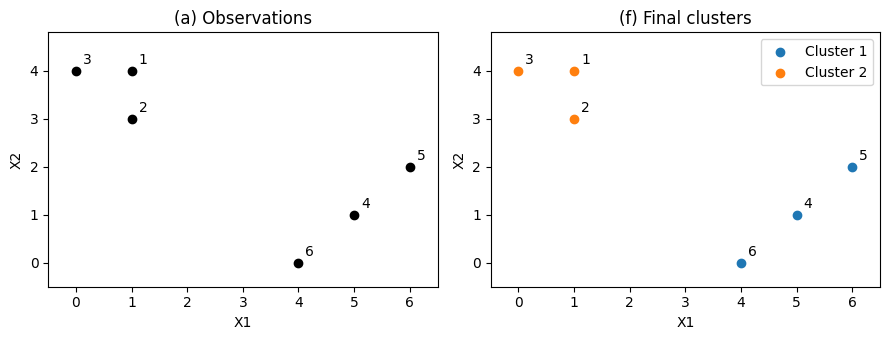

In [2]:
points = np.array([
    [1, 4],
    [1, 3],
    [0, 4],
    [5, 1],
    [6, 2],
    [4, 0]
])

rng_manual = np.random.default_rng(42)
initial_labels = rng_manual.integers(1, 3, size=6)
print("Initial labels:", initial_labels)

final_labels = np.array([2, 2, 2, 1, 1, 1])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

axes[0].scatter(points[:, 0], points[:, 1], color="black")

for cluster, color in [(1, "tab:blue"), (2, "tab:orange")]:
    mask = final_labels == cluster
    axes[1].scatter(
        points[mask, 0], points[mask, 1],
        color=color, label=f"Cluster {cluster}"
    )

for ax, title in zip(
    axes, ["(a) Observations", "(f) Final clusters"]
):
    for obs, (x1, x2) in enumerate(points, start=1):
        ax.annotate(
            str(obs), (x1, x2),
            xytext=(5, 5), textcoords="offset points"
        )
    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-0.5, 6.5)
    ax.set_ylim(-0.5, 4.8)

axes[1].legend()
plt.tight_layout()
plt.show()


### 12.6.4 Linkage and merge heights

**(a)** For A = {1, 2, 3} and B = {4, 5}, complete linkage uses
the maximum pairwise dissimilarity between A and B, whereas
single linkage uses the minimum. Therefore, the complete-linkage
fusion occurs at an equal or greater height. It is strictly higher
unless all cross-cluster dissimilarities are equal.

**(b)** Both clusters are singletons, so both methods use the
same dissimilarity d(5, 6). They merge at the same height.

### 12.6.5 Effects of variable scaling

**Raw purchase counts (left):** Sock purchases have much greater
variation than computer purchases. K-means would mainly separate
shoppers with high versus low sock purchases.

**Scaled variables (center):** Dividing each variable by its
standard deviation gives both variables equal variance. The clusters
would reflect both sock and computer purchasing patterns, rather
than being dominated by one product.

**Dollar amounts (right):** Computer spending has much greater
variation because computers are more expensive. K-means would
mainly separate shoppers with high versus low computer spending.

### 12.6.6 Obtaining PCA loadings by regression

For centered data and known principal component scores, Equation
(12.6) minimizes

$$
\sum_{j=1}^{p}\sum_{i=1}^{n}
\left(x_{ij}-\sum_{m=1}^{M}z_{im}\phi_{jm}\right)^2.
$$

The objective separates into p least squares problems, one per
feature j. In each regression, the response is the feature vector
$x_{\cdot j}$, the predictors are the M score vectors, and the
coefficients are the loadings $\phi_{j1},\ldots,\phi_{jM}$.

Writing Z for the score matrix, the solution is

$$
\hat{\phi}_j=(Z^\top Z)^{-1}Z^\top x_{\cdot j},
$$

provided Z has full column rank. Since the data and PCA scores
are centered, no intercept is needed. Combining the coefficients
from the p regressions gives the first M loading vectors.

### 12.6.7 Correlation and Euclidean distance

I standardize each observation across its p features to have
mean zero and sample standard deviation one.

For standardized observations u and v,

$$
\begin{aligned}
\|u-v\|^2
&=\sum_{j=1}^{p}u_j^2+\sum_{j=1}^{p}v_j^2
-2\sum_{j=1}^{p}u_jv_j\\
&=2(p-1)-2(p-1)r_{uv}\\
&=2(p-1)(1-r_{uv}).
\end{aligned}
$$

USArrests has p = 4 features, so the proportionality constant is 6.
The following calculation verifies this relationship numerically.

In [3]:
url = (
    "https://vincentarelbundock.github.io/"
    "Rdatasets/csv/datasets/USArrests.csv"
)

arrests = pd.read_csv(url, index_col=0)

A = arrests.to_numpy()
A_row_scaled = (
    (A - A.mean(axis=1, keepdims=True))
    / A.std(axis=1, ddof=1, keepdims=True)
)

squared_distances = squareform(
    pdist(A_row_scaled, metric="sqeuclidean")
)
correlations = np.corrcoef(A_row_scaled)
expected_distances = 2 * (A.shape[1] - 1) * (1 - correlations)

print("Data shape:", arrests.shape)
print("Proportionality constant:", 2 * (A.shape[1] - 1))
print(
    "Maximum absolute difference:",
    f"{np.max(np.abs(squared_distances - expected_distances)):.2e}"
)
print(
    "Relationship verified:",
    np.allclose(squared_distances, expected_distances)
)


Data shape: (50, 4)
Proportionality constant: 6
Maximum absolute difference: 1.93e-15
Relationship verified: True


### 12.6.8 Two ways to calculate PVE

I center each variable and scale it to sample standard deviation one.

(a) I calculate PVE by dividing each principal component's variance
by the total variance. This is equivalent to normalizing the squared
standard deviations returned by R's prcomp().

(b) I apply Equation (12.10) directly: I project the standardized
data onto each loading vector, sum the squared scores, and divide
by the total sum of squares of the standardized data.

Both methods use the same standardized data.

In [4]:
A_scaled = (A - A.mean(axis=0)) / A.std(axis=0, ddof=1)

pca_arrests = PCA(svd_solver="full")
pca_arrests.fit(A_scaled)

# (a) Normalize the principal component variances.
pc_variances = pca_arrests.explained_variance_
pve_a = pc_variances / pc_variances.sum()

# (b) Apply Equation (12.10) using the loading vectors.
loadings = pca_arrests.components_.T
scores = A_scaled @ loadings
pve_b = (scores ** 2).sum(axis=0) / (A_scaled ** 2).sum()

pve_results = pd.DataFrame(
    {
        "(a) Variance-based PVE": pve_a,
        "(b) Direct PVE": pve_b
    },
    index=["PC1", "PC2", "PC3", "PC4"]
)

display(pve_results.round(6))
print("Methods agree:", np.allclose(pve_a, pve_b))


,(a) Variance-based PVE,(b) Direct PVE
PC1,0.620060,0.620060
PC2,0.247441,0.247441
PC3,0.089141,0.089141
PC4,0.043358,0.043358


Methods agree: True


### 12.6.9 Hierarchical clustering of US states

(a)–(b) I apply complete-linkage hierarchical clustering with
Euclidean distance to the original variables and cut the tree
at a height that gives three clusters.

(c) I repeat the clustering after scaling each variable to
sample standard deviation one.

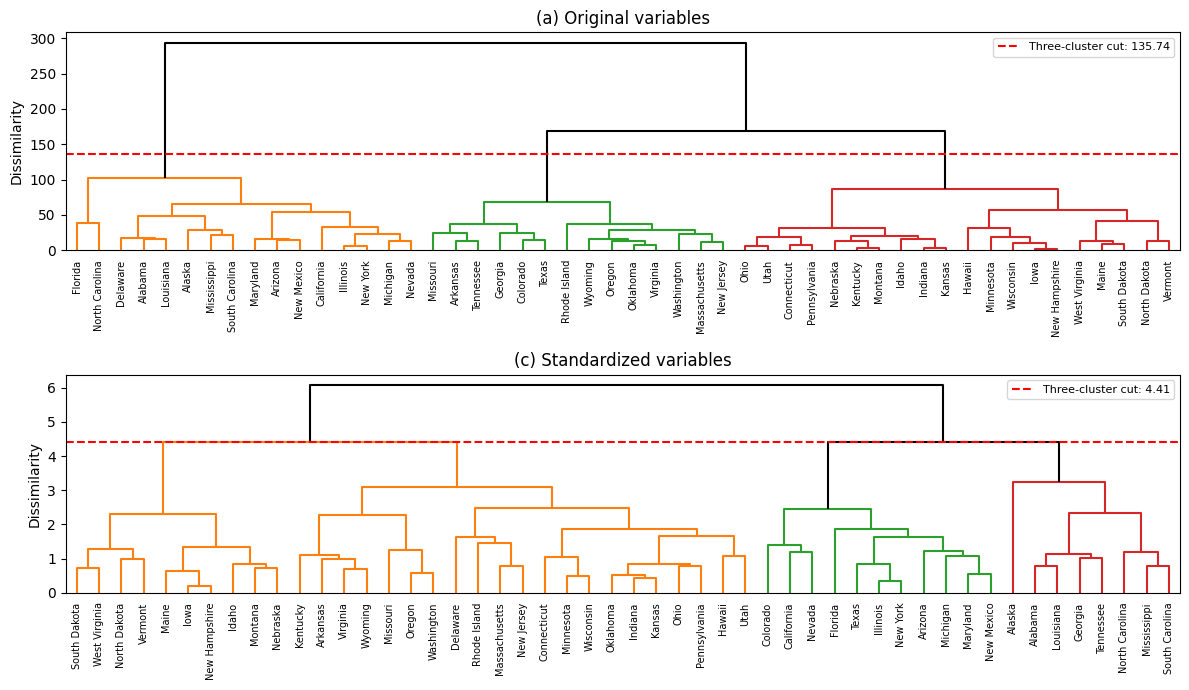

(b) Clusters using original variables:

Cluster 1 (16 states):
Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states):
Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states):
Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin

Original vs. standardized cluster assignments:


Standardized,1,2,3
Original,,,
1,6,9,1
2,2,2,10
3,0,0,20


In [5]:
Z_raw = linkage(A, method="complete", metric="euclidean")
Z_scaled = linkage(A_scaled, method="complete", metric="euclidean")

raw_groups = cut_tree(Z_raw, n_clusters=3).ravel() + 1
scaled_groups = cut_tree(Z_scaled, n_clusters=3).ravel() + 1

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax, Z, title in zip(
    axes,
    [Z_raw, Z_scaled],
    ["(a) Original variables", "(c) Standardized variables"]
):
    cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

    dendrogram(
        Z,
        labels=arrests.index.tolist(),
        leaf_rotation=90,
        leaf_font_size=7,
        color_threshold=cut_height,
        above_threshold_color="black",
        ax=ax
    )

    ax.axhline(
        cut_height, color="red", linestyle="--",
        label=f"Three-cluster cut: {cut_height:.2f}"
    )
    ax.set_title(title)
    ax.set_ylabel("Dissimilarity")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("(b) Clusters using original variables:")
for cluster in range(1, 4):
    states = arrests.index[raw_groups == cluster]
    print(f"\nCluster {cluster} ({len(states)} states):")
    print(", ".join(states))

print("\nOriginal vs. standardized cluster assignments:")
display(pd.crosstab(
    pd.Series(raw_groups, name="Original"),
    pd.Series(scaled_groups, name="Standardized")
))


#### (d)

Scaling changes the relative contributions of the variables to
Euclidean distance and can therefore change cluster memberships
and the dendrogram.

In the original data, Assault has much greater variance than the
other variables and strongly influences the distances. After scaling,
each variable has variance one.

I would scale these variables because they measure different
quantities, including crime rates and the percentage of the population
living in urban areas. Standardization prevents numerical scale alone
from determining each variable's influence.

### 12.6.10 PCA and K-means on simulated data

#### (a)–(b)

I generate 60 observations with 50 features, with 20 observations
in each of three classes. Independent standard normal noise is
added to each observation. Class 2 has a mean shift of 3 in the
first 25 features, while Class 3 has a mean shift of 3 in the
last 25 features.

I plot the first two principal component scores, colored by true class.

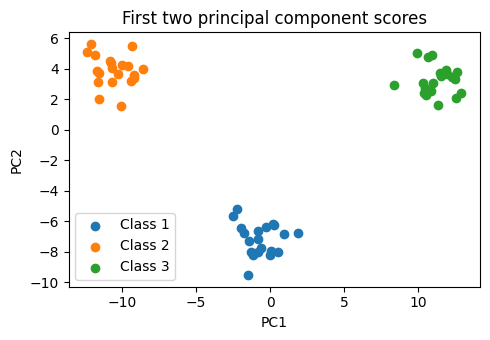

In [6]:
rng_sim = np.random.default_rng(42)

X_sim = rng_sim.normal(size=(60, 50))
true_sim = np.repeat([1, 2, 3], 20)

X_sim[20:40, :25] += 3
X_sim[40:60, 25:] += 3

pca_sim = PCA(n_components=2, svd_solver="full")
sim_scores = pca_sim.fit_transform(X_sim)

fig, ax = plt.subplots(figsize=(5, 3.5))

for label in [1, 2, 3]:
    mask = true_sim == label
    ax.scatter(
        sim_scores[mask, 0],
        sim_scores[mask, 1],
        label=f"Class {label}"
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("First two principal component scores")
ax.legend()
plt.tight_layout()
plt.show()


#### (c)–(g)
I compare K = 3, 2, and 4 on the original data, K = 3 on the first
two PC scores, and K = 3 on standardized features. Contingency tables
are shown for (c)–(e); the final table reports ARI for all five settings.
ARI is invariant to cluster numbering, and ARI = 1 indicates perfect
agreement with the true classes.


In [7]:
X_sim_scaled = (
    (X_sim - X_sim.mean(axis=0))
    / X_sim.std(axis=0, ddof=1)
)

sim_settings = [
    ("(c) Original, K=3", X_sim, 3),
    ("(d) Original, K=2", X_sim, 2),
    ("(e) Original, K=4", X_sim, 4),
    ("(f) First two PCs, K=3", sim_scores, 3),
    ("(g) Standardized, K=3", X_sim_scaled, 3)
]

sim_rows = []

with threadpool_limits(limits=1):
    for name, features, k in sim_settings:
        clusters = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=42
        ).fit_predict(features)

        if name.startswith(("(c)", "(d)", "(e)")):
            print(name)
            display(pd.crosstab(
                pd.Series(true_sim, name="True class"),
                pd.Series(clusters + 1, name="Cluster")
            ))

        sim_rows.append({
            "Setting": name,
            "ARI": adjusted_rand_score(true_sim, clusters)
        })

display(pd.DataFrame(sim_rows).set_index("Setting").round(4))


(c) Original, K=3


Cluster,1,2,3
True class,,,
1,0,0,20
2,20,0,0
3,0,20,0


(d) Original, K=2


Cluster,1,2
True class,,
1,20,0
2,20,0
3,0,20


(e) Original, K=4


Cluster,1,2,3,4
True class,,,,
1,20,0,0,0
2,0,0,9,11
3,0,20,0,0


,ARI
Setting,
"(c) Original, K=3",1.0000
"(d) Original, K=2",0.5630
"(e) Original, K=4",0.8658
"(f) First two PCs, K=3",1.0000
"(g) Standardized, K=3",1.0000


#### Results for (b)–(g)

(b) The first two principal components clearly separate the three classes.

(c) K-means with K = 3 on the original data perfectly recovers
the three classes (ARI = 1). Cluster numbers differ from class
numbers, but memberships agree.

(d) With K = 2, Classes 1 and 2 merge into one cluster, while
Class 3 remains separate (ARI = 0.5630).

(e) With K = 4, Class 2 splits into clusters of 9 and 11 observations.
Classes 1 and 3 remain intact (ARI = 0.8658).

(f) Using only the first two principal component scores also
perfectly recovers the classes (ARI = 1). Here, the first two
components preserve the separation needed for clustering.

(g) Standardizing the features also gives perfect recovery
(ARI = 1), consistent with the separation visible in (b).
The simulated features have comparable scales and strong mean
differences, so scaling does not change the recovered groups.

### 12.6.11 Matrix completion
I implement Algorithm 12.1 using rank-M SVD approximations. Missing
entries start at observed column means; each iteration updates only
missing entries. Observed entries remain fixed.

The function records iteration count, observed-entry reconstruction MSE,
and relative change $|E_{t-1}-E_t|/B$, where B is the mean squared observed
value. It stops at a relative change below $10^{-7}$ or 1,000 iterations,
and optionally prints progress. A callback is included for Exercise 12.

I standardize all 14 Boston columns before masking. For each of 10 seeds,
one random ordering defines nested missing-entry sets from 5% to 30%.
All M = 1, ..., 8 use the same masks. I report mean hidden-entry MSE
across repetitions; preprocessing before masking follows the exercise.


In [8]:
boston_url = (
    "https://vincentarelbundock.github.io/"
    "Rdatasets/csv/MASS/Boston.csv"
)

boston = pd.read_csv(boston_url, index_col=0)

B = boston.to_numpy(dtype=float)
B_scaled = (B - B.mean(axis=0)) / B.std(axis=0, ddof=1)

print("Boston shape:", B_scaled.shape)
print("Missing values:", np.isnan(B_scaled).sum())
print(
    "Columns standardized:",
    np.allclose(B_scaled.mean(axis=0), 0)
    and np.allclose(B_scaled.std(axis=0, ddof=1), 1)
)


Boston shape: (506, 14)
Missing values: 0
Columns standardized: True


In [9]:
def matrix_complete(X_missing, M, tol=1e-7,
                    max_iter=1000, verbose=False,
                    rank_approx=None):
    X_missing = np.asarray(X_missing, dtype=float)
    missing = np.isnan(X_missing)
    observed = ~missing

    column_means = np.nanmean(X_missing, axis=0)
    if np.isnan(column_means).any():
        raise ValueError("A column has no observed values.")

    completed = np.where(missing, column_means, X_missing)
    baseline = np.mean(X_missing[observed] ** 2)
    baseline = max(baseline, np.finfo(float).eps)

    previous_error = None
    history = []
    converged = False

    for iteration in range(1, max_iter + 1):
        if rank_approx is None:
            U, s, Vt = np.linalg.svd(completed, full_matrices=False)
            approximation = (U[:, :M] * s[:M]) @ Vt[:M, :]
        else:
            approximation = rank_approx(completed, M)

        error = np.mean(
            (X_missing[observed] - approximation[observed]) ** 2
        )

        relative_change = (
            np.inf if previous_error is None
            else abs(previous_error - error) / baseline
        )

        completed[missing] = approximation[missing]

        history.append({
            "Iteration": iteration,
            "Observed MSE": error,
            "Relative change": relative_change
        })

        if verbose:
            print(
                f"Iteration {iteration}: "
                f"MSE={error:.6f}, "
                f"relative change={relative_change:.2e}"
            )

        if relative_change < tol:
            converged = True
            break

        previous_error = error

    return completed, pd.DataFrame(history), converged


In [10]:
rng_completion = np.random.default_rng(42)

pilot_mask = np.zeros(B_scaled.size, dtype=bool)
pilot_indices = rng_completion.permutation(B_scaled.size)
pilot_mask[pilot_indices[:int(0.05 * B_scaled.size)]] = True
pilot_mask = pilot_mask.reshape(B_scaled.shape)

B_missing = B_scaled.copy()
B_missing[pilot_mask] = np.nan


with threadpool_limits(limits=1):
    B_completed, completion_history, converged = matrix_complete(
        B_missing, M=2
    )

hidden_mse = np.mean(
    (B_completed[pilot_mask] - B_scaled[pilot_mask]) ** 2
)

print("Converged:", converged)
print("Iterations:", len(completion_history))
print("Hidden-entry MSE:", round(hidden_mse, 6))
print(
    "Observed entries unchanged:",
    np.array_equal(
        B_completed[~pilot_mask], B_scaled[~pilot_mask]
    )
)


Converged: True
Iterations: 8
Hidden-entry MSE: 0.560394
Observed entries unchanged: True


In [11]:
missing_rates = np.arange(1, 7) / 20
completion_rows = []

with threadpool_limits(limits=1):
    for repetition in range(10):
        rng = np.random.default_rng(42 + repetition)
        order = rng.permutation(B_scaled.size)

        for rate in missing_rates:
            mask = np.zeros(B_scaled.size, dtype=bool)
            mask[order[:int(rate * B_scaled.size)]] = True
            mask = mask.reshape(B_scaled.shape)

            B_masked = B_scaled.copy()
            B_masked[mask] = np.nan

            for M in range(1, 9):
                filled, history, converged = matrix_complete(
                    B_masked, M=M
                )

                mse = np.mean(
                    (filled[mask] - B_scaled[mask]) ** 2
                )

                completion_rows.append({
                    "Repetition": repetition + 1,
                    "Missing proportion": rate,
                    "M": M,
                    "Hidden MSE": mse,
                    "Iterations": len(history),
                    "Converged": converged
                })


completion_results = pd.DataFrame(completion_rows)

print(
    "Fits reaching the iteration limit:",
    (~completion_results["Converged"]).sum()
)


Fits reaching the iteration limit: 214


M,1,2,3,4,5,6,7,8
Missing proportion,,,,,,,,
0.05,0.5849,0.5393,0.5170,1.5768,2.4410,6.1834,7.6033,6.4344
0.10,0.6152,0.5813,0.5649,6.3038,6.8476,9.8584,8.2717,7.8239
0.15,0.6250,0.6007,0.6167,5.0530,5.4166,8.0230,7.5769,7.2547
0.20,0.6179,0.6065,0.6306,3.6492,4.3778,6.6566,6.9450,7.2302
0.25,0.6280,0.6264,0.6871,3.3404,4.1101,7.1087,6.9257,6.1034
0.30,0.6218,0.6378,0.7532,3.4304,3.9871,6.2713,6.2287,5.8112


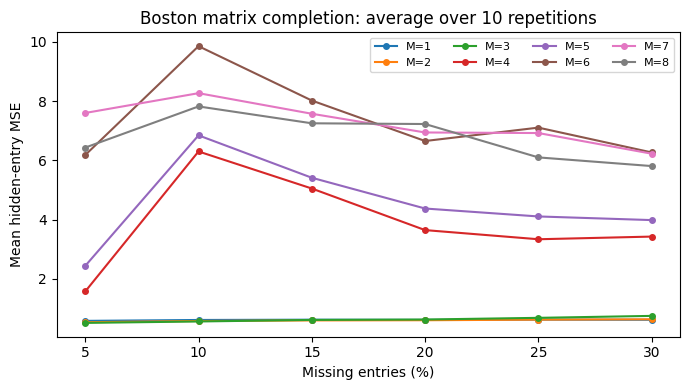

In [12]:
completion_mean = completion_results.pivot_table(
    index="Missing proportion",
    columns="M",
    values="Hidden MSE",
    aggfunc="mean"
)

display(completion_mean.round(4))

fig, ax = plt.subplots(figsize=(7, 4))

for M in completion_mean.columns:
    ax.plot(
        completion_mean.index * 100,
        completion_mean[M],
        marker="o",
        markersize=4,
        label=f"M={M}"
    )

ax.set_xlabel("Missing entries (%)")
ax.set_ylabel("Mean hidden-entry MSE")
ax.set_title("Boston matrix completion: average over 10 repetitions")
ax.set_xticks([5, 10, 15, 20, 25, 30])
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()


In [13]:
completion_diagnostics = completion_results.groupby("M").agg(
    Fits=("Converged", "size"),
    Converged_fits=("Converged", "sum"),
    Mean_iterations=("Iterations", "mean")
)

completion_diagnostics["Reached_limit"] = (
    completion_diagnostics["Fits"]
    - completion_diagnostics["Converged_fits"]
)

completion_diagnostics.round(1)


,Fits,Converged_fits,Mean_iterations,Reached_limit
M,,,,
1,60,60,9.6,0
2,60,60,22.8,0
3,60,60,52.0,0
4,60,29,639.9,31
5,60,24,811.6,36
6,60,14,915.0,46
7,60,9,947.3,51
8,60,10,954.7,50


M = 3 gives the lowest mean hidden-entry MSE at 5%–10% missingness,
M = 2 at 15%–20%, and M = 1 at 25%–30%. More components do not
necessarily improve predictions of unobserved entries.

All fits with M = 1, 2, or 3 converged. Of 480 fits, 214 reached the
1,000-iteration limit, all with M >= 4. Higher-rank results describe
this fixed iteration budget and may be affected by incomplete convergence.
Observed-entry convergence alone does not guarantee accurate imputation.


### 12.6.12 Matrix completion using PCA
I supply a PCA reconstruction callback to the same iteration function.
To match the uncentered SVD, I fit PCA to the stacked matrices X and -X.
This has zero column means and preserves the eigenvectors of $X^	op X$.
With the first M loading vectors V, the reconstruction is $XVV^	op$.
Initialization, updates, and stopping criteria are unchanged.
The pilot below compares PCA and SVD using the same 5% mask and M = 2.


In [14]:
def pca_rank_approx(X, M):
    pca = PCA(n_components=M, svd_solver="full")
    pca.fit(np.vstack([X, -X]))
    V = pca.components_.T
    return (X @ V) @ V.T

def matrix_complete_pca(X_missing, M, tol=1e-7,
                        max_iter=1000, verbose=False):
    return matrix_complete(
        X_missing,
        M=M,
        tol=tol,
        max_iter=max_iter,
        verbose=verbose,
        rank_approx=pca_rank_approx
    )

with threadpool_limits(limits=1):
    pca_completed, pca_history, pca_converged = (
        matrix_complete_pca(B_missing, M=2)
    )

print("PCA converged:", pca_converged)
print("PCA iterations:", len(pca_history))
print(
    "Matches SVD completion:",
    np.allclose(pca_completed, B_completed)
)
print(
    "PCA hidden-entry MSE:",
    round(np.mean(
        (pca_completed[pilot_mask] - B_scaled[pilot_mask]) ** 2
    ), 6)
)


PCA converged: True
PCA iterations: 8
Matches SVD completion: True
PCA hidden-entry MSE: 0.560394


### 12.6.13 Gene expression data

#### (a)–(b)

I load the data without a header and transpose it so that rows
represent the 40 tissue samples and columns represent the 1,000 genes.
Samples 1–20 are healthy, and samples 21–40 are diseased.

I use correlation distance, 1 - r, between samples and compare
complete, average, and single linkage. Each tree is cut into two
clusters, and agreement with the true groups is measured using ARI.

Source: https://www.statlearning.com/s/Ch12Ex13.csv

In [15]:
gene_url = "https://www.statlearning.com/s/Ch12Ex13.csv"
gene_data = pd.read_csv(gene_url, header=None)

G = gene_data.to_numpy(dtype=float).T
assert G.shape == (40, 1000)

gene_groups = np.array(["Healthy"] * 20 + ["Diseased"] * 20)
sample_names = (
    [f"H{i}" for i in range(1, 21)]
    + [f"D{i}" for i in range(1, 21)]
)

print("Samples × genes:", G.shape)
print("Missing values:", np.isnan(G).sum())


Samples × genes: (40, 1000)
Missing values: 0


Complete linkage:


Cluster,1,2
True group,,
Diseased,0,20
Healthy,10,10


Average linkage:


Cluster,1,2
True group,,
Diseased,0,20
Healthy,9,11


Single linkage:


Cluster,1,2
True group,,
Diseased,20,0
Healthy,19,1


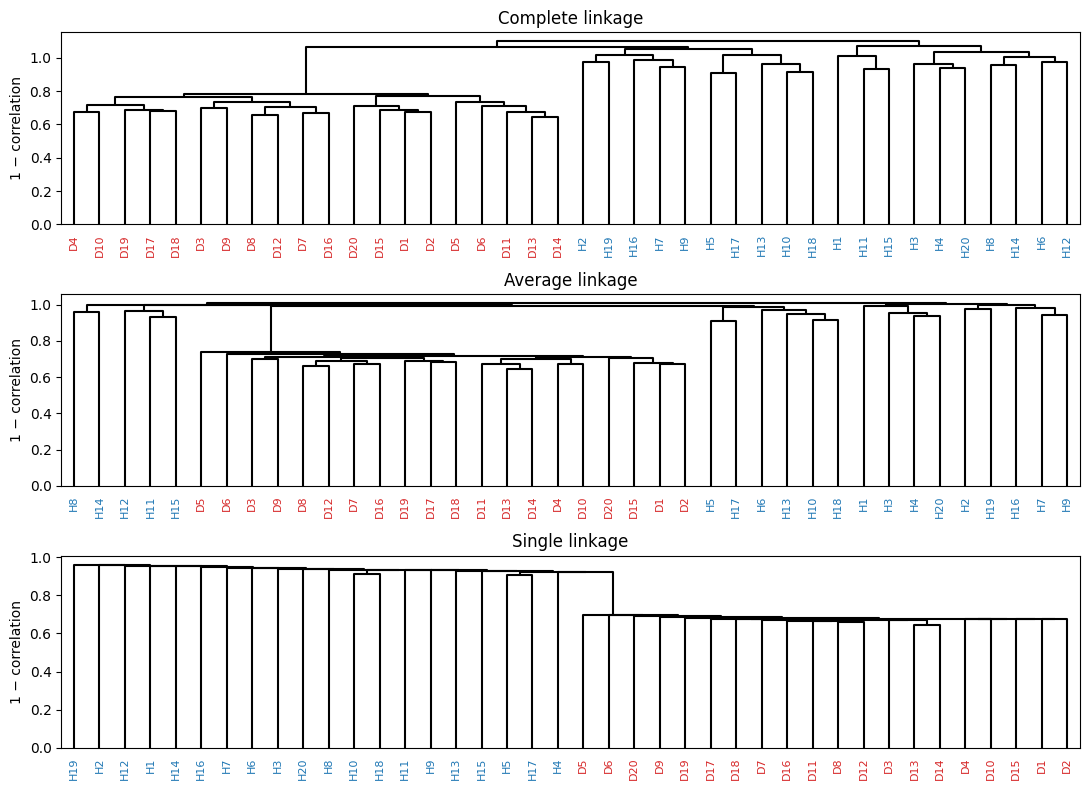

,ARI
Linkage,
complete,0.2353
average,0.1880
single,0.0000


In [16]:
gene_distances = pdist(G, metric="correlation")
gene_cluster_rows = []

fig, axes = plt.subplots(3, 1, figsize=(11, 8))

for ax, method in zip(axes, ["complete", "average", "single"]):
    Z_gene = linkage(gene_distances, method=method)
    clusters = cut_tree(Z_gene, n_clusters=2).ravel()

    dendrogram(
        Z_gene,
        labels=sample_names,
        leaf_rotation=90,
        leaf_font_size=8,
        color_threshold=0,
        above_threshold_color="black",
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} linkage")
    ax.set_ylabel("1 − correlation")

    for tick in ax.get_xticklabels():
        tick.set_color(
            "tab:blue" if tick.get_text().startswith("H")
            else "tab:red"
        )

    gene_cluster_rows.append({
        "Linkage": method,
        "ARI": adjusted_rand_score(gene_groups, clusters)
    })

    print(f"{method.capitalize()} linkage:")
    display(pd.crosstab(
        pd.Series(gene_groups, name="True group"),
        pd.Series(clusters + 1, name="Cluster")
    ))

plt.tight_layout()
plt.show()

display(
    pd.DataFrame(gene_cluster_rows)
    .set_index("Linkage")
    .round(4)
)


Complete and average linkage place all 20 diseased samples in
one cluster, together with 10 and 11 healthy samples, respectively.
Their ARIs are 0.2353 and 0.1880.

Single linkage produces one cluster containing 39 samples and
another containing one healthy sample, giving an ARI of 0.

Thus, the diseased samples show a recognizable grouping, but cutting
the trees into two clusters does not perfectly recover health status.
The results depend on linkage, with complete linkage giving the
highest ARI among the three methods tested.

#### (c) Genes differing between the two groups

I rank genes by the absolute difference in mean expression between
diseased and healthy samples. Positive differences indicate higher
mean expression in the diseased group.

I also perform a two-sided Welch t-test for each gene and apply
Benjamini–Hochberg correction across all 1,000 tests.
Mean differences measure effect magnitude, while adjusted p-values
provide complementary evidence accounting for within-group variation.

Gene numbers refer to the original CSV row numbers, starting at 1.

In [17]:
healthy = G[:20]
diseased = G[20:]

mean_difference = diseased.mean(axis=0) - healthy.mean(axis=0)

t_stats, p_values = ttest_ind(
    diseased, healthy, axis=0, equal_var=False
)

# Benjamini–Hochberg adjustment across all genes.
n_genes = len(p_values)
order = np.argsort(p_values)
sorted_p = p_values[order]

adjusted_sorted = np.minimum.accumulate(
    (sorted_p * n_genes / np.arange(1, n_genes + 1))[::-1]
)[::-1]

adjusted_p = np.empty(n_genes)
adjusted_p[order] = np.clip(adjusted_sorted, 0, 1)

gene_results = pd.DataFrame({
    "Gene": np.arange(1, n_genes + 1),
    "Mean difference": mean_difference,
    "Absolute difference": np.abs(mean_difference),
    "Welch t": t_stats,
    "p-value": p_values,
    "BH-adjusted p": adjusted_p
})

top_genes = gene_results.sort_values(
    ["Absolute difference", "Gene"],
    ascending=[False, True]
).head(10)

display(
    top_genes.set_index("Gene").style.format({
        "Mean difference": "{:.4f}",
        "Absolute difference": "{:.4f}",
        "Welch t": "{:.4f}",
        "p-value": "{:.2e}",
        "BH-adjusted p": "{:.2e}"
    })
)

print(
    "Genes with BH-adjusted p < 0.05:",
    (adjusted_p < 0.05).sum()
)


,Mean difference,Absolute difference,Welch t,p-value,BH-adjusted p
Gene,,,,,
600,2.7476,2.7476,9.6234,1.00e-11,3.35e-09
584,2.6020,2.6020,7.8771,2.13e-09,2.67e-07
549,2.5508,2.5508,6.8112,7.03e-08,1.50e-06
540,2.5452,2.5452,7.4481,1.38e-08,5.32e-07
502,2.5445,2.5445,10.3167,1.53e-12,1.53e-09
568,2.5194,2.5194,6.7145,6.34e-08,1.41e-06
582,2.4961,2.4961,6.4031,1.64e-07,3.09e-06
565,2.4708,2.4708,8.6287,1.77e-10,3.53e-08
562,2.4655,2.4655,7.1186,1.71e-08,5.53e-07


Genes with BH-adjusted p < 0.05: 117


Genes 600, 584, and 549 have the largest absolute mean differences
between the groups, approximately 2.7476, 2.6020, and 2.5508.
All ten genes shown have higher mean expression in the diseased group.

Across all 1,000 genes, 117 have Benjamini–Hochberg-adjusted
p-values below 0.05. These are statistical candidates for further
investigation; statistical significance alone does not establish
biological importance.